# Torres de Hanoi con aprendizaje por refuerzo
**Nombre:** Condori Cuevas Jhon Carlos Ing. de Sistemas
<br>
**Link Repositorio:** https://github.com/jccondoric/machine_learning/blob/master/Parciales/Segundo_Parcial/2/torre_de_hanoi.ipynb <br>


## El juego

Hay 3 postes y 7 discos de distinto tamaño, apilados al inicio en el poste A (el más grande abajo y el más pequeño arriba). Los postes se llaman A, B y C. El objetivo es llevar todos los discos al poste C cumpliendo dos reglas:

- Solo se mueve un disco por turno: el que está en la cima de un poste.
- Nunca se puede poner un disco grande sobre uno más pequeño.

Con $n$ discos el mínimo de movimientos es $2^n - 1$, es decir, **127** con 7 discos. El número de estados posibles es $3^n = 2187$, ya que cada disco puede estar en uno de los 3 postes.

<div align="center">
  <img src="https://drive.google.com/uc?export=view&id=146qqJdiVp9G6pWk6LvOUM3BgC_IE9kQj" width="350" alt="Torres de Hanói">
</div>


## Planteamiento

A diferencia del tres en raya, aquí hay un solo jugador, por lo que no hace falta un oponente ni autojuego. Los elementos son:

- **Entorno**: la torre, con su estado y sus reglas.
- **Estado**: una tupla de 7 números donde la posición $i$ indica en qué poste está el disco $i$ (el 0 es el más pequeño). Los postes A, B y C se guardan como 0, 1 y 2. Por ejemplo `(0, 0, 0, 0, 0, 0, 0)` es el inicio y `(2, 2, 2, 2, 2, 2, 2)` es la meta.
- **Acciones**: los 6 movimientos posibles entre postes `(origen, destino)`: AB, AC, BA, BC, CA y CB. En cualquier estado el agente puede elegir cualquiera de las 6, aunque solo algunas son legales.
- **Recompensa**: -1 por cada movimiento realizado. Como el agente quiere maximizar la recompensa total, le conviene llegar a la meta con la menor cantidad de movimientos. Si intenta un movimiento ilegal (por ejemplo poner un disco grande sobre uno pequeño) el disco no se mueve, el estado no cambia y recibe -10. Así el agente también aprende las reglas por sí solo, porque los movimientos ilegales le salen caros.
- **Función de valor**: una tabla $Q(s, a)$ con el valor de cada acción en cada estado, como en el notebook del tres en raya pero guardando el valor de las acciones, porque aquí el siguiente estado depende solo de la acción elegida.
- **Política**: elegir la acción con mayor valor entre las 6, sin filtrar cuáles son legales, y con probabilidad `prob_exp` una acción aleatoria para explorar (equilibrio entre exploración y explotación).

La actualización de la tabla se hace después de cada movimiento:

$$
Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma \max_{a} Q(S_{t+1}, a) - Q(S_t, A_t) \right]
$$

donde $\alpha$ es el ratio de aprendizaje y $\gamma$ el factor de descuento. Es el método Q-learning tabular, la versión más básica de axr sin ninguna técnica avanzada.

La tabla se inicia en 0. Como todas las recompensas son negativas, cualquier acción probada vale menos que una sin probar, así que el agente tiende a probar acciones nuevas de forma natural. Cuando hay empate entre acciones se elige al azar.

In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from tqdm import tqdm

## Número de discos

El juego funciona con cualquier cantidad de discos. Para cambiarla basta con modificar `N_DISCOS`

In [2]:
N_DISCOS = 7

## Entorno

La clase `Torre` guarda el estado, calcula los movimientos válidos, aplica un movimiento y detecta si el juego terminó. El método `step` es el que usa el agente al entrenar: si el movimiento es legal lo hace y devuelve -1, y si es ilegal no cambia nada y devuelve -10.

In [3]:
ACCIONES = [(0, 1), (0, 2), (1, 0), (1, 2), (2, 0), (2, 1)]
LETRAS = 'ABC'
PENALIZACION = -10


class Torre:
    def __init__(self, n_discos=7):
        self.n_discos = n_discos
        self.state = tuple([0] * n_discos)

    def reset(self):
        self.state = tuple([0] * self.n_discos)

    def tope(self, poste):
        for disco in range(self.n_discos):
            if self.state[disco] == poste:
                return disco
        return None

    def valid_moves(self):
        movimientos = []
        for ix, (origen, destino) in enumerate(ACCIONES):
            disco = self.tope(origen)
            if disco is None:
                continue
            tope_destino = self.tope(destino)
            if tope_destino is None or disco < tope_destino:
                movimientos.append(ix)
        return movimientos

    def update(self, accion):
        if accion not in self.valid_moves():
            raise ValueError('movimiento ilegal')
        origen, destino = ACCIONES[accion]
        disco = self.tope(origen)
        nuevo = list(self.state)
        nuevo[disco] = destino
        self.state = tuple(nuevo)

    def step(self, accion):
        if accion not in self.valid_moves():
            return PENALIZACION
        self.update(accion)
        return -1

    def is_game_over(self):
        return all(poste == 2 for poste in self.state)

## Agente

La clase `Agent` guarda la tabla `q` (un diccionario estado → vector con el valor de las 6 acciones). El método `move` implementa la política y `update` la actualización de Q-learning. El agente no consulta qué movimientos son legales: elige entre las 6 acciones y aprende cuáles no sirven por la penalización.

In [4]:
class Agent:
    def __init__(self, alpha=0.5, gamma=1.0, prob_exp=0.05):
        self.q = {}
        self.alpha = alpha
        self.gamma = gamma
        self.prob_exp = prob_exp

    def valores(self, state):
        if state not in self.q:
            self.q[state] = np.zeros(len(ACCIONES))
        return self.q[state]

    def move(self, board, explore=True):
        if explore and np.random.uniform(0, 1) < self.prob_exp:
            return int(np.random.choice(len(ACCIONES)))
        q = self.valores(board.state)
        candidatos = np.flatnonzero(q == q.max())
        return int(np.random.choice(candidatos))

    def update(self, state, accion, reward, board):
        q = self.valores(state)
        if board.is_game_over():
            objetivo = reward
        else:
            objetivo = reward + self.gamma * self.valores(board.state).max()
        q[accion] += self.alpha * (objetivo - q[accion])

## Entrenamiento

Cada episodio empieza con todos los discos en el poste A. El agente elige una acción, recibe la recompensa (-1, o -10 si fue ilegal) y actualiza su tabla hasta llegar a la meta o hasta agotar `max_pasos`, un límite para que un episodio no dure para siempre al principio, cuando el agente todavía se mueve casi al azar. Cada intento cuenta como un paso, también los ilegales. Guardamos cuántos pasos tardó en cada episodio para ver cómo mejora.

In [5]:
def entrenar(agent, board, episodios, max_pasos):
    historial = []
    for _ in tqdm(range(episodios)):
        board.reset()
        pasos = 0
        while not board.is_game_over() and pasos < max_pasos:
            estado = board.state
            accion = agent.move(board)
            recompensa = board.step(accion)
            agent.update(estado, accion, recompensa, board)
            pasos += 1
        historial.append(pasos)
    return historial

In [6]:
np.random.seed(0)

torre = Torre(n_discos=N_DISCOS)
agente = Agent(alpha=0.5, gamma=1.0, prob_exp=0.05)

historial = entrenar(agente, torre, episodios=3000, max_pasos=2000)

len(agente.q)

100%|██████████| 3000/3000 [01:35<00:00, 31.51it/s]


2186

La tabla tiene 2186 estados: los 2187 posibles del juego menos el estado meta, desde el cual el agente ya no necesita actuar. Veamos cuántos pasos necesitó el agente en cada episodio:

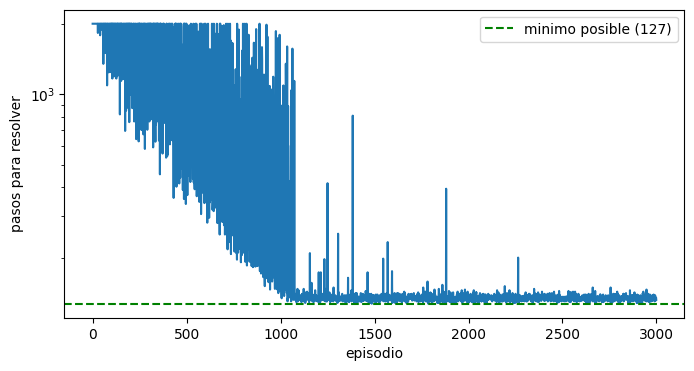

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(historial)
plt.axhline(2 ** N_DISCOS - 1, color='green', linestyle='--', label=f'minimo posible ({2 ** N_DISCOS - 1})')
plt.xlabel('episodio')
plt.ylabel('pasos para resolver')
plt.yscale('log')
plt.legend()
plt.show()

Al principio el agente necesita muchos pasos, casi al azar (hasta llegar al límite de 2000), y poco a poco va bajando hasta estabilizarse cerca del mínimo. Lo que queda por encima de 127 son los movimientos aleatorios de exploración que sigue haciendo durante el entrenamiento, incluidos algunos intentos ilegales.

## Evaluación

Evaluamos al agente sin exploración (`explore=False`), es decir, usando solo lo aprendido. Lo comparamos con el mínimo teórico $2^n - 1$ y contamos cuántos intentos ilegales hace: si aprendió las reglas, deberían ser 0.

In [8]:
def resolver(agent, board, max_intentos=3000):
    board.reset()
    movimientos = []
    ilegales = 0
    intentos = 0
    while not board.is_game_over() and intentos < max_intentos:
        accion = agent.move(board, explore=False)
        if accion in board.valid_moves():
            board.update(accion)
            movimientos.append(ACCIONES[accion])
        else:
            ilegales += 1
        intentos += 1
    return movimientos, ilegales

movimientos, ilegales = resolver(agente, torre)

print('resuelto:', torre.is_game_over())
print('movimientos del agente:', len(movimientos))
print('intentos ilegales del agente:', ilegales)
print('minimo posible:', 2 ** torre.n_discos - 1)

resuelto: True
movimientos del agente: 127
intentos ilegales del agente: 0
minimo posible: 127


## Ver la solución

Dibujamos la torre en modo texto. Cada poste se muestra de abajo hacia arriba con el tamaño de cada disco (1 es el más pequeño).

In [9]:
def dibujar_torre(board):
    postes = [[], [], []]
    for disco in reversed(range(board.n_discos)):
        postes[board.state[disco]].append(disco + 1)
    print('')
    for nivel in reversed(range(board.n_discos)):
        fila = []
        for poste in postes:
            fila.append(str(poste[nivel]) if nivel < len(poste) else '|')
        print('   '.join(f'{x:>2}' for x in fila))
    print('-- ' * 3 + '\n A    B    C\n')


def mostrar_solucion(agent, board, pasos_a_mostrar=None):
    movimientos, _ = resolver(agent, Torre(board.n_discos))
    board.reset()
    print('Inicio')
    dibujar_torre(board)
    for paso, (origen, destino) in enumerate(movimientos, 1):
        board.update(ACCIONES.index((origen, destino)))
        if pasos_a_mostrar is None or paso <= pasos_a_mostrar:
            print(f'Paso {paso}: poste {LETRAS[origen]} -> poste {LETRAS[destino]}')
            dibujar_torre(board)
    if board.is_game_over():
        print(f'Meta alcanzada en {len(movimientos)} pasos')
    else:
        print('El agente no logro resolver el juego')
    dibujar_torre(board)

In [10]:
mostrar_solucion(agente, Torre(N_DISCOS), pasos_a_mostrar=5)

Inicio

 1    |    |
 2    |    |
 3    |    |
 4    |    |
 5    |    |
 6    |    |
 7    |    |
-- -- -- 
 A    B    C

Paso 1: poste A -> poste C

 |    |    |
 2    |    |
 3    |    |
 4    |    |
 5    |    |
 6    |    |
 7    |    1
-- -- -- 
 A    B    C

Paso 2: poste A -> poste B

 |    |    |
 |    |    |
 3    |    |
 4    |    |
 5    |    |
 6    |    |
 7    2    1
-- -- -- 
 A    B    C

Paso 3: poste C -> poste B

 |    |    |
 |    |    |
 3    |    |
 4    |    |
 5    |    |
 6    1    |
 7    2    |
-- -- -- 
 A    B    C

Paso 4: poste A -> poste C

 |    |    |
 |    |    |
 |    |    |
 4    |    |
 5    |    |
 6    1    |
 7    2    3
-- -- -- 
 A    B    C

Paso 5: poste B -> poste A

 |    |    |
 |    |    |
 1    |    |
 4    |    |
 5    |    |
 6    |    |
 7    2    3
-- -- -- 
 A    B    C

Meta alcanzada en 127 pasos

 |    |    1
 |    |    2
 |    |    3
 |    |    4
 |    |    5
 |    |    6
 |    |    7
-- -- -- 
 A    B    C



## Probar con otras cantidades de discos

El entorno funciona con cualquier número de discos. Entrenamos un agente nuevo con 3 discos, donde la solución mínima son 7 movimientos.

In [11]:
np.random.seed(1)

torre3 = Torre(n_discos=3)
agente3 = Agent()
entrenar(agente3, torre3, episodios=500, max_pasos=200)

mostrar_solucion(agente3, torre3)

100%|██████████| 500/500 [00:00<00:00, 1807.62it/s]

Inicio

 1    |    |
 2    |    |
 3    |    |
-- -- -- 
 A    B    C

Paso 1: poste A -> poste C

 |    |    |
 2    |    |
 3    |    1
-- -- -- 
 A    B    C

Paso 2: poste A -> poste B

 |    |    |
 |    |    |
 3    2    1
-- -- -- 
 A    B    C

Paso 3: poste C -> poste B

 |    |    |
 |    1    |
 3    2    |
-- -- -- 
 A    B    C

Paso 4: poste A -> poste C

 |    |    |
 |    1    |
 |    2    3
-- -- -- 
 A    B    C

Paso 5: poste B -> poste A

 |    |    |
 |    |    |
 1    2    3
-- -- -- 
 A    B    C

Paso 6: poste B -> poste C

 |    |    |
 |    |    2
 1    |    3
-- -- -- 
 A    B    C

Paso 7: poste A -> poste C

 |    |    1
 |    |    2
 |    |    3
-- -- -- 
 A    B    C

Meta alcanzada en 7 pasos

 |    |    1
 |    |    2
 |    |    3
-- -- -- 
 A    B    C



## Jugar contra el agente

Ahora puedes resolver el juego tú mismo. Cada movimiento se escribe con la letra del poste de origen y la del poste de destino, por ejemplo `AC` mueve el disco de arriba del poste A al poste C. Si escribes `S` te rindes.

El juego revisa las dos reglas y te explica por qué un movimiento no es válido. Cuando terminas, el agente resuelve el mismo juego desde el principio y se comparan los movimientos de los dos con el mínimo posible.

Con 7 discos el mínimo son 127 movimientos, así que aquí se juega con 3 discos (7 movimientos como mínimo). Para jugar con el número de discos principal se usa `jugar_humano(agente, N_DISCOS)`.

In [12]:
def pedir_movimiento(board):
    while True:
        entrada = input('Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): ').strip().upper()
        if entrada == 'S':
            return None
        if len(entrada) != 2 or entrada[0] not in LETRAS or entrada[1] not in LETRAS:
            print('Entrada invalida. Escribe dos letras entre A, B y C.')
            continue
        origen = LETRAS.index(entrada[0])
        destino = LETRAS.index(entrada[1])
        if origen == destino:
            print('El origen y el destino deben ser distintos.')
            continue
        disco = board.tope(origen)
        if disco is None:
            print(f'El poste {entrada[0]} esta vacio.')
            continue
        tope_destino = board.tope(destino)
        if tope_destino is not None and tope_destino < disco:
            print(f'Movimiento ilegal: el disco {disco + 1} es mas grande que el {tope_destino + 1} del poste {entrada[1]}.')
            continue
        return ACCIONES.index((origen, destino))


def jugar_humano(agent, n_discos=3):
    board = Torre(n_discos)
    movimientos_humano = 0

    print(f'Lleva los {n_discos} discos del poste A al poste C.')
    dibujar_torre(board)

    while not board.is_game_over():
        accion = pedir_movimiento(board)
        if accion is None:
            break
        board.update(accion)
        movimientos_humano += 1
        dibujar_torre(board)

    if board.is_game_over():
        print(f'Lo resolviste en {movimientos_humano} movimientos.')
    else:
        print(f'Te rendiste despues de {movimientos_humano} movimientos.')

    movimientos_agente, _ = resolver(agent, Torre(n_discos))

    print('')
    print(f'Tus movimientos:        {movimientos_humano}')
    print(f'Movimientos del agente: {len(movimientos_agente)}')
    print(f'Minimo posible:         {2 ** n_discos - 1}')
    print('Solucion del agente: ' + ' '.join(LETRAS[o] + LETRAS[d] for o, d in movimientos_agente))

In [13]:
jugar_humano(agente3, 3)

Lleva los 3 discos del poste A al poste C.

 1    |    |
 2    |    |
 3    |    |
-- -- -- 
 A    B    C

Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): AB

 |    |    |
 2    |    |
 3    1    |
-- -- -- 
 A    B    C

Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): AC

 |    |    |
 |    |    |
 3    1    2
-- -- -- 
 A    B    C

Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): AC
Movimiento ilegal: el disco 3 es mas grande que el 2 del poste C.
Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): BC

 |    |    |
 |    |    1
 3    |    2
-- -- -- 
 A    B    C

Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): AB

 |    |    |
 |    |    1
 |    3    2
-- -- -- 
 A    B    C

Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): CB

 |    |    |
 |    1    |
 |    3    2
-- -- -- 
 A    B    C

Tu movimiento (origen y destino, por ejemplo AC. S para rendirte): CA

 |    |    |
 | 

## Guardar el agente

Guardamos la función de valor entrenada con `pickle`

In [14]:
with open('agente_hanoi.pickle', 'wb') as handle:
    pickle.dump(agente.q, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [15]:
with open('agente_hanoi.pickle', 'rb') as handle:
    q_cargada = pickle.load(handle)

agente_cargado = Agent()
agente_cargado.q = q_cargada

movimientos, _ = resolver(agente_cargado, Torre(N_DISCOS))
len(movimientos)

127